# SBI experiments — recover δ from raw CB data

Thin driver. The reusable machinery lives in `.py` modules:
- `sbi_data.py` — load parquet → 36 features → standardized train/test tensors
- `gaussian_net.py` — the Gaussian-output MLP baseline (the control)
- `conditional_diffusion.py` — the diffusion estimator *(to build)*
- `sbi_eval.py` — shared eval harness (identical metrics + plots for every model)

This notebook just imports them, trains, and compares.

*(The fully-annotated build — NLL derivation, layer-by-layer comments — lives in
git history at commit `97efa5c`, file `SBI_model.ipynb`.)*

In [1]:
%load_ext autoreload
%autoreload 2

import torch
import pandas as pd
from sbi_data     import load_features
from gaussian_net import train_gaussian
from sbi_eval     import report

In [2]:
# data: 2000 runs -> 36 features -> standardized train/test tensors
Xtr, ytr, Xte, yte, feature_cols = load_features()
print("train:", Xtr.shape, ytr.shape, "| test:", Xte.shape, yte.shape)

# peek at the actual data: standardized 36 features + the δ target, one row per run
train_view = pd.DataFrame(Xtr.numpy(), columns=feature_cols)
train_view.insert(0, "δ (target)", ytr.numpy().ravel())
display(train_view.head())
display(train_view.tail())

train: torch.Size([8000, 36]) torch.Size([8000, 1]) | test: torch.Size([2000, 36]) torch.Size([2000, 1])


,δ (target),mean_X2,mean_X4,mean_X6,mean_X8,mean_X12,mean_X16,mean_Y2,mean_Y4,mean_Y6,...,var_Y6,var_Y8,var_Y12,var_Y16,var_Z2,var_Z4,var_Z6,var_Z8,var_Z12,var_Z16
0,0.171181,-0.499428,-0.378037,-0.887657,0.304294,-0.346207,-0.542446,-1.542044,-0.288334,-0.792689,...,0.184093,0.886856,0.787026,-0.275620,1.192658,0.795238,1.746387,0.828301,0.373462,-0.293657
1,0.155403,0.128291,-0.096657,-0.445975,-0.399633,-0.655257,-0.912066,-0.409992,0.010305,-0.337409,...,-0.041106,0.798973,0.681050,0.388792,0.457918,0.165904,-0.194353,-0.227336,0.877897,0.121056
2,0.103460,0.459091,0.768364,0.417668,0.494849,0.446385,0.412671,0.447254,0.269007,0.601500,...,-0.446585,-0.773854,0.111529,0.226133,-0.731201,-0.488261,-0.685576,-0.953985,0.156343,-0.256580
3,0.094875,0.521506,0.683353,0.685580,0.855902,0.747804,0.581155,0.530918,0.720736,0.713477,...,-0.706274,-0.884173,-0.134357,0.303180,-0.779536,-0.625361,-0.697659,-0.678458,-0.126107,-0.399682
4,0.027714,1.185782,1.225731,1.273125,1.328530,1.397445,1.478447,1.637228,1.591359,1.439203,...,-1.076270,-1.256737,-1.600213,-1.851214,-1.317950,-1.148601,-1.173568,-1.317966,-1.656544,-1.903353


,δ (target),mean_X2,mean_X4,mean_X6,mean_X8,mean_X12,mean_X16,mean_Y2,mean_Y4,mean_Y6,...,var_Y6,var_Y8,var_Y12,var_Y16,var_Z2,var_Z4,var_Z6,var_Z8,var_Z12,var_Z16
7995,0.187828,-0.547577,-0.685766,-0.800958,-1.326397,-0.715032,-0.613649,-1.575510,-0.361108,-1.030818,...,0.943949,0.995407,0.126783,1.577182,1.135194,0.673948,1.570828,0.355337,0.701957,0.668535
7996,0.193021,-0.880161,-1.082980,-1.241152,-0.632813,-0.594719,-0.805715,-0.497518,-0.876292,-0.841732,...,1.185100,1.280149,0.342886,1.231165,0.710535,1.002542,1.407863,0.431415,0.772374,0.753764
7997,0.166346,-0.790996,-0.585344,-0.557605,-0.566996,-0.522735,-0.542673,-1.030400,-0.376638,-0.379648,...,-0.199203,1.262040,1.121130,0.382758,0.696054,0.457940,0.731058,1.610518,1.629434,0.600513
7998,0.108717,0.660603,0.419870,0.521856,0.547816,0.386610,0.648276,0.124178,0.491766,0.400508,...,-0.560356,-0.680921,0.402700,0.147194,-0.413183,-0.653024,-0.806625,-0.673938,0.728965,0.863798
7999,0.173917,-0.473570,-1.196824,-0.644676,-0.518417,-1.532043,-0.417501,-0.604352,-0.406813,-0.739393,...,0.039601,1.123169,-0.261464,-0.416960,1.192894,0.313580,0.868932,0.751795,0.466822,0.231436


## Model 1 — Gaussian net (baseline / control)

In [3]:
gnet = train_gaussian(Xtr, ytr, epochs=2000)

epoch   0  train NLL -0.3543  val NLL -0.3815
epoch 100  train NLL -2.8809  val NLL -2.7919
epoch 200  train NLL -3.4030  val NLL -3.1230
epoch 300  train NLL -3.8279  val NLL -3.7059
epoch 400  train NLL -3.6153  val NLL -3.5894
epoch 500  train NLL -4.2343  val NLL -3.8391
epoch 600  train NLL -4.4783  val NLL -4.2686
epoch 700  train NLL -4.6143  val NLL -4.3486
epoch 800  train NLL -4.4090  val NLL -4.2722
epoch 900  train NLL -3.4085  val NLL -4.1800
epoch 1000  train NLL -4.5874  val NLL -4.3826
epoch 1100  train NLL -2.5383  val NLL -4.2030
epoch 1200  train NLL -4.1849  val NLL -4.1189
epoch 1300  train NLL -4.7407  val NLL -4.4623
epoch 1400  train NLL -4.2504  val NLL -4.2591
epoch 1500  train NLL -4.8067  val NLL -4.5506
epoch 1600  train NLL -1.7047  val NLL -2.8000
epoch 1700  train NLL -4.1944  val NLL -4.1314
epoch 1800  train NLL -4.7396  val NLL -4.5243
epoch 1900  train NLL -5.0285  val NLL -4.6339
restored best (by val NLL): -4.6384


[Gaussian net]
  test RMSE      : 0.0050   (delta spans 0.02-0.25)
  test NLL       : -4.6786
  within +/-1 sig: 70.2%   (ideal 68%)
  within +/-2 sig: 90.8%   (ideal 95%)
  std of z       : 1.22   (ideal 1.0)
  fraction|z|>2  : 9.2%   (ideal ~4.6%)


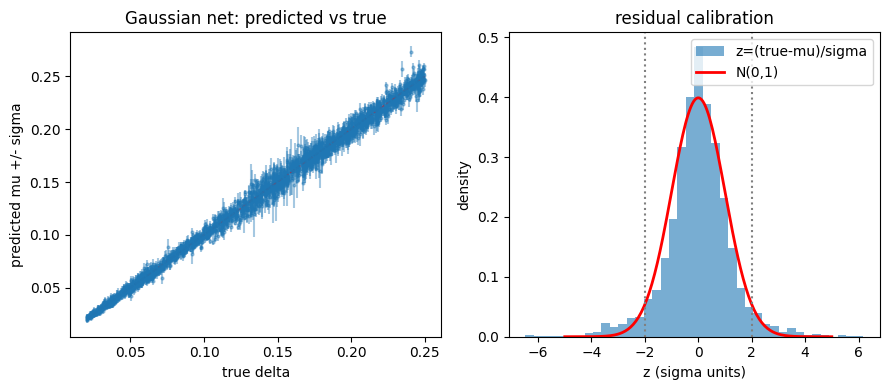

{'rmse': 0.00500711,
 'nll': -4.678565,
 'cov1': 0.7015,
 'cov2': 0.9085,
 'z_std': 1.2210091}

In [4]:
gnet.eval()
with torch.no_grad():
    mu, sigma = gnet(Xte)
report(mu, sigma, yte, title="Gaussian net")

## Model 2 — conditional diffusion *(to build)*